## Functional preprocessing

### Loading libraries and data visualization

In [2]:
import sys
import os
import os.path as op
import glob
import subprocess

# to use utils.py functions
notebook_dir = os.path.abspath("")
parent_dir = os.path.abspath(os.path.join(notebook_dir, '..'))
sys.path.append(parent_dir)
sys.path.append('.')
from utils import loadFSL, FSLeyesServer, mkdir_no_exist

# load fsl in neurodesk
import module as lmod
await lmod.purge(force=True)
await lmod.load('fsl/6.0.7.18')
await lmod.list()
loadFSL()

# Wrapper FSL usati
from fsl.wrappers import fslmaths, mcflirt
from fsl.wrappers.misc import fslroi

# analysis and plots
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from nilearn import plotting, image
from nilearn.masking import compute_epi_mask

In [3]:
%gui wx


(ipykernel_launcher.py:3145): dbind-WARNING **: 12:39:23.804: Couldn't connect to accessibility bus: Failed to connect to socket /run/user/1402404120/at-spi/bus_100: No such file or directory


In [4]:
#start FSLeyes
fsleyesDisplay = FSLeyesServer()
fsleyesDisplay.show()

12:39:28: Debug: Adding duplicate image handler for 'Windows bitmap file'
12:39:28: Debug: Adding duplicate animation handler for '1' type
12:39:28: Debug: Adding duplicate animation handler for '2' type
12:39:28: Debug: Adding duplicate image handler for 'Windows bitmap file'
12:39:28: Debug: Adding duplicate animation handler for '1' type
12:39:28: Debug: Adding duplicate animation handler for '2' type

(ipykernel_launcher.py:3145): Gtk-CRITICAL **: 12:39:28.529: gtk_window_resize: assertion 'width > 0' failed

(ipykernel_launcher.py:3145): Gtk-CRITICAL **: 12:39:30.372: gtk_window_resize: assertion 'width > 0' failed


In [5]:
#creating path variables (to be executed everytime)

fmri_path = op.join(notebook_dir,'dataset','fMRI','tfMRI_LANGUAGE_LR','tfMRI_LANGUAGE_LR.nii.gz')
derivatives = op.join(notebook_dir,'dataset','derivatives')
derivatives_anat = op.join(derivatives,'anat')
derivatives_func = op.join(derivatives,'func')

In [6]:
#visualizing fMRI data before all the preprocessing steps
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(fmri_path)


(ipykernel_launcher.py:3145): Gtk-WARNING **: 12:44:36.027: Negative content width -11 (allocation 9, extents 10x10) while allocating gadget (node button, owner GtkButton)

(ipykernel_launcher.py:3145): Gtk-WARNING **: 12:44:36.027: Negative content height -2 (allocation 8, extents 5x5) while allocating gadget (node button, owner GtkButton)


### Motion correction

#### Throwing away first volumes for magnetic field 

Text(0, 0.5, 'Mean voxel intensity')

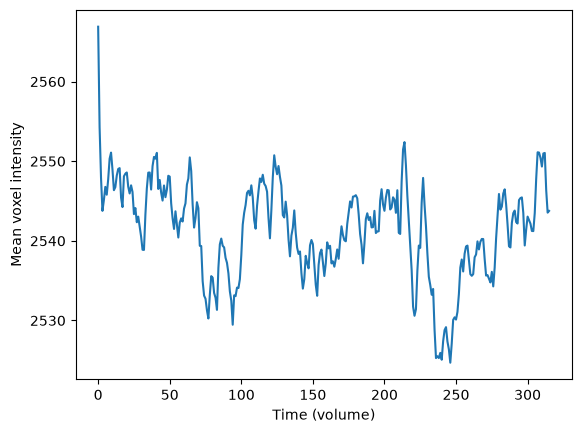

In [10]:
# check if there are some non stationary volumes at the beginning

plt.plot(nib.load(fmri_path).get_fdata().mean(axis=(0,1,2)))
plt.xlabel('Time (volume)')
plt.ylabel('Mean voxel intensity')

In [7]:
# Removing first volumes to make sure the magnetic field of the scanner is settled
file_to_trim = glob.glob(fmri_path)[0]
path_settled_fmri = op.join(derivatives_func,'tfMRI_LANGUAGE_LR_settled.nii.gz')

start_vol = 5
n_tot = nib.load(fmri_path).shape[-1]
number_of_volumes = n_tot - start_vol # How many volumes should we keep?

# Function creating new nifti with trimmed number of volumes
fslroi(file_to_trim, path_settled_fmri, str(start_vol), str(number_of_volumes))
print(f"You kept {nib.load(path_settled_fmri).shape[-1]} volumes.")

You kept 311 volumes.


### Actual motion correction with mcflirt

In [10]:
# motion correction
path_moco_data = op.join(derivatives_func,'tfMRI_LANGUAGE_LR_moco')
mcflirt(infile=path_settled_fmri,o=path_moco_data, plots=True, report=True, dof=6, mats=True, meanvol = True) # using mean vol as ref volume 



Processed data will be saved as derivatives_func/tfMRI_LANGUAGE_LR_moco

McFLIRT v 2.0 - FMRI motion correction

Reading time series... 
first iteration - 8mm scaling, set tolerance
Rescaling reference volume [155] to 8 mm pixels
Registering volumes ... [156][157][158][159][160][161][162][163][164][165][166][167][168][169][170][171][172][173][174][175][176][177][178][179][180][181][182][183][184][185][186][187][188][189][190][191][192][193][194][195][196][197][198][199][200][201][202][203][204][205][206][207][208][209][210][211][212][213][214][215][216][217][218][219][220][221][222][223][224][225][226][227][228][229][230][231][232][233][234][235][236][237][238][239][240][241][242][243][244][245][246][247][248][249][250][251][252][253][254][255][256][257][258][259][260][261][262][263][264][265][266][267][268][269][270][271][272][273][274][275][276][277][278][279][280][281][282][283][284][285][286][287][288][289][290][291][292][293][294][295][296][297][298][299][300][301][302][303][304][

{}

In [18]:
#visualizing moco
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(path_settled_fmri)
fsleyesDisplay.load(path_moco_data)


(ipykernel_launcher.py:1170): Gtk-WARNING **: 16:03:29.832: Negative content width -11 (allocation 9, extents 10x10) while allocating gadget (node button, owner GtkButton)

(ipykernel_launcher.py:1170): Gtk-WARNING **: 16:03:29.832: Negative content height -2 (allocation 8, extents 5x5) while allocating gadget (node button, owner GtkButton)


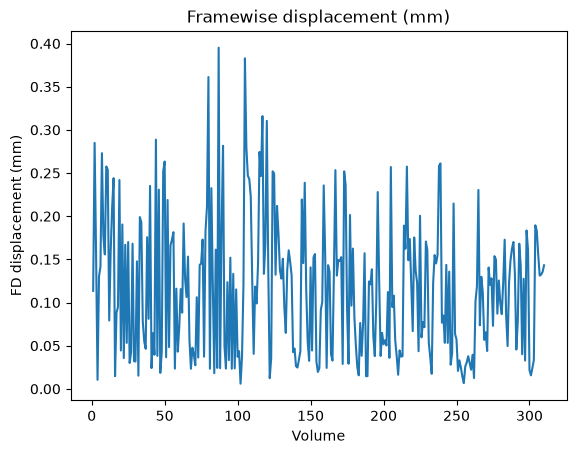

In [8]:
#visualizing framewise displacement
def load_mot_params_fsl_6_dof(path):
    return pd.read_csv(path, sep='  ', header=None, 
            engine='python', names=['Rotation x', 'Rotation y', 'Rotation z','Translation x', 'Translation y', 'Translation z'])

mot_params = load_mot_params_fsl_6_dof(op.join(derivatives_func,'tfMRI_LANGUAGE_LR_moco.par'))

def compute_FD_power(mot_params):
    framewise_diff = mot_params.diff().iloc[1:]

    rot_params = framewise_diff[['Rotation x', 'Rotation y', 'Rotation z']]
    # Estimating displacement on a 50mm radius sphere
    converted_rots = rot_params*50
    trans_params = framewise_diff[['Translation x', 'Translation y', 'Translation z']]
    fd = converted_rots.abs().sum(axis=1) + trans_params.abs().sum(axis=1)
    return fd

fd = compute_FD_power(mot_params).to_numpy()

plt.plot(list(range(1, fd.size+1)), fd)
plt.xlabel('Volume')
plt.ylabel('FD displacement (mm)')
plt.title("Framewise displacement (mm)")
plt.show()


volume 292, displacement from mean volume ≈ 0.27 mm


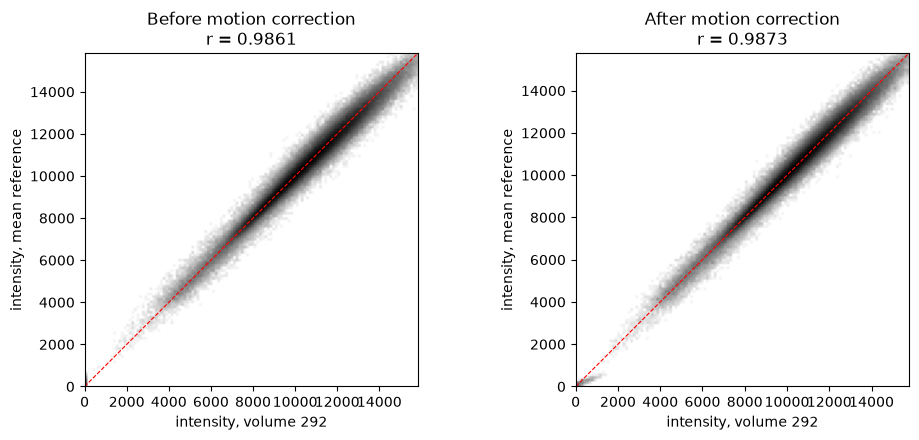

In [9]:
#plotting joint histogram (of ref volume, in this case mean volume against another vol) before and after motion correction
# note for AI statement: the code in this cell was written by claude
settled_path = op.join(derivatives_func, 'tfMRI_LANGUAGE_LR_settled.nii.gz')
moco_path    = op.join(derivatives_func, 'tfMRI_LANGUAGE_LR_moco.nii.gz')
ref_path     = op.join(derivatives_func, 'tfMRI_LANGUAGE_LR_moco_mean_reg.nii.gz')
par_path     = op.join(derivatives_func, 'tfMRI_LANGUAGE_LR_moco.par')

settled, moco = nib.load(settled_path), nib.load(moco_path)
ref = nib.load(ref_path).get_fdata()
assert settled.ndim == 4 and moco.ndim == 4 and ref.ndim == 3

# volume più spostato rispetto al riferimento
par = np.loadtxt(par_path)
disp = 50 * np.abs(par[:, :3]).sum(1) + np.abs(par[:, 3:]).sum(1)
t = int(np.argmax(disp))
print(f"volume {t}, displacement from mean volume ≈ {disp[t]:.2f} mm") #volume with the highest displacement from the ref

before = np.asarray(settled.dataobj[..., t], dtype=float)
after  = np.asarray(moco.dataobj[..., t], dtype=float)
mask = compute_epi_mask(moco_path).get_fdata().astype(bool)

def joint_hist(ax, src, ref, title, bins=128):
    x, y = src[mask], ref[mask]
    lim = np.percentile(np.concatenate([x, y]), 99.5)
    h, _, _ = np.histogram2d(x, y, bins=bins, range=[[0, lim], [0, lim]])
    ax.imshow(h.T, origin='lower', extent=[0, lim, 0, lim],
              norm=LogNorm(vmin=1), cmap='Greys', aspect='equal')
    ax.plot([0, lim], [0, lim], 'r--', lw=0.8)
    ax.set(title=f"{title}\nr = {np.corrcoef(x, y)[0, 1]:.4f}",
           xlabel=f'intensity, volume {t}', ylabel='intensity, mean reference')

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
joint_hist(axes[0], before, ref, 'Before motion correction')
joint_hist(axes[1], after,  ref, 'After motion correction')
plt.tight_layout()
plt.show()

### Gaussian smoothing
Followed the recommendation from the slides: FWHM = twice voxel size (in this case the voxel size is 2 mm)

In [14]:
# gaussian smoothing
print(moco.header.get_zooms())   # The first three numbers are the voxel dimensions in mm (x, y, z), and the fourth is the TR in seconds.
fwhm = 4                                                    # mm, 2 × voxel size
in_path  = op.join(derivatives_func, 'tfMRI_LANGUAGE_LR_moco') 
out_path = f'{in_path}_smoothed-{fwhm}mm'

subprocess.run(['fslmaths', in_path, '-s', str(fwhm / 2.3548), out_path], check=True)
print(nib.load(out_path + '.nii.gz').shape)                 # should still be (91, 109, 91, 311)

(np.float32(2.0), np.float32(2.0), np.float32(2.0), np.float32(0.72))
(91, 109, 91, 311)


In [16]:
fsleyesDisplay.load(out_path) #visualizing spatial smoothing


(ipykernel_launcher.py:824): Gtk-WARNING **: 09:46:20.657: Negative content width -11 (allocation 9, extents 10x10) while allocating gadget (node button, owner GtkButton)


### Validate alignment between anatomical and functional data
Overlay the fMRI data to the structural data you previously registered to MNI space. Report a plot of the overlay at one fMRI volume and section of your choice and comment on the general quality of the alignment. Is there a fMRI preprocessing step that can be avoided given what you see? Justify your answer based on the plot

In [10]:
# validate alignment
registered_anat = os.path.join(derivatives_anat, 'T1w_mni.nii.gz')
moco_smoothed_func = os.path.join(derivatives,'tfMRI_LANGUAGE_LR_moco_smoothed-4mm.nii.gz')


In [10]:
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(registered_anat)
fsleyesDisplay.load(moco_smoothed_func)


(ipykernel_launcher.py:975): Gtk-WARNING **: 12:20:00.865: Negative content width -11 (allocation 9, extents 10x10) while allocating gadget (node button, owner GtkButton)

(ipykernel_launcher.py:975): Gtk-WARNING **: 12:20:00.865: Negative content height -2 (allocation 8, extents 5x5) while allocating gadget (node button, owner GtkButton)


In [11]:
#checking right orientation
for name, p in [('fMRI', moco_smoothed_func), ('T1', registered_anat)]:
    img = nib.load(p)
    print(name, img.shape[:3], img.header.get_zooms()[:3],
          nib.aff2axcodes(img.affine), 'sform_code =', img.header.get_sform(coded=True)[1])

fMRI (91, 109, 91) (np.float32(2.0), np.float32(2.0), np.float32(2.0)) ('L', 'A', 'S') sform_code = 4
T1 (182, 218, 182) (np.float32(1.0), np.float32(1.0), np.float32(1.0)) ('L', 'A', 'S') sform_code = 1
